Page 1: 20 books
Page 2: 20 books
Page 3: 20 books
Page 4: 20 books
Page 5: 20 books
Page 6: 20 books
Page 7: 20 books
Page 8: 20 books
Page 9: 20 books
Page 10: 20 books
Page 11: 20 books
Page 12: 20 books
Page 13: 20 books
Page 14: 20 books
Page 15: 20 books
Page 16: 20 books
Page 17: 20 books
Page 18: 20 books
Page 19: 20 books
Page 20: 20 books
Page 21: 20 books
Page 22: 20 books
Page 23: 20 books
Page 24: 20 books
Page 25: 20 books
Page 26: 20 books
Page 27: 20 books
Page 28: 20 books
Page 29: 20 books
Page 30: 20 books
Page 31: 20 books
Page 32: 20 books
Page 33: 20 books
Page 34: 20 books
Page 35: 20 books
Page 36: 20 books
Page 37: 20 books
Page 38: 20 books
Page 39: 20 books
Page 40: 20 books
Page 41: 20 books
Page 42: 20 books
Page 43: 20 books
Page 44: 20 books
Page 45: 20 books
Page 46: 20 books
Page 47: 20 books
Page 48: 20 books
Page 49: 20 books
Page 50: 20 books

First rows:
                                   Title  Price  Rating Availability  \
0                   A Li

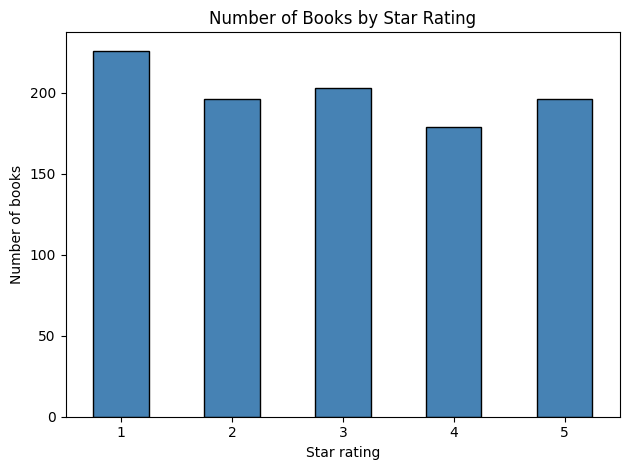


===== RECOMMENDATION =====
I would prioritise the 4 and 5star books, starting with the cheaper 5 star titles. Only 19.6% of the catalogue is rated 5 stars, so these books are scarce and likely to be popular with customers. Their average price (£35.37) is close to the overall average (£35.07), so strong quality does not need premium pricing, and 100% of the competitor's stock is available, meaning we should keep good stock levels to compete.


In [2]:
"""
Bookstore Intelligence Mission
Scrapes books.toscrape.com, builds a DataFrame, saves competitor_books.csv
and answers the analysis questions.
"""

import re
import time
from urllib.parse import urljoin

import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt

BASE_URL = "https://books.toscrape.com/catalogue/"
PAGE_URL = BASE_URL + "page-{}.html"
NUM_PAGES = 50   # whole catalogue (boss level). Set to 5 or 3 for a quicker run.

RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}


def scrape_page(page_number):
    """Scrape one catalogue page and return a list of dicts (one per book)."""
    url = PAGE_URL.format(page_number)
    response = requests.get(url, timeout=15)
    response.encoding = "utf-8"
    if response.status_code != 200:
        print(f"Page {page_number} failed with status {response.status_code}")
        return []

    soup = BeautifulSoup(response.text, "html.parser")
    books = []

    for card in soup.find_all("article", class_="product_pod"):
        link = card.h3.a
        title = link["title"]
        product_url = urljoin(BASE_URL, link["href"])

        price_text = card.find("p", class_="price_color").text
        price = float(re.sub(r"[^\d.]", "", price_text))

        # rating is stored in the class, e.g. class="star-rating Three"
        rating_word = card.find("p", class_="star-rating")["class"][1]
        rating = RATING_MAP[rating_word]

        availability = card.find("p", class_="instock availability").text.strip()

        books.append({
            "Title": title,
            "Price": price,
            "Rating": rating,
            "Availability": availability,
            "URL": product_url,
        })

    return books


# ---------- Mission 2 + 3: scrape pages in a loop ----------
all_books = []
for page in range(1, NUM_PAGES + 1):
    page_books = scrape_page(page)
    all_books.extend(page_books)
    print(f"Page {page}: {len(page_books)} books")
    time.sleep(0.3)   # be polite to the server

df = pd.DataFrame(all_books)
df.to_csv("competitor_books.csv", index=False)

print("\nFirst rows:")
print(df.head())
print("\nShape:", df.shape)
print(df.dtypes)


# ---------- Mission 4: analysis ----------
print("\n===== INTELLIGENCE ANALYSIS =====")

priciest = df.loc[df["Price"].idxmax()]
cheapest = df.loc[df["Price"].idxmin()]
print(f"1. Most expensive: {priciest['Title']} (£{priciest['Price']:.2f})")
print(f"2. Cheapest: {cheapest['Title']} (£{cheapest['Price']:.2f})")
print(f"3. Average price: £{df['Price'].mean():.2f}")

five_star = df[df["Rating"] == 5]
print(f"4. Number of 5-star books: {len(five_star)}")

in_stock_pct = (df["Availability"] == "In stock").mean() * 100
print(f"5. Percentage in stock: {in_stock_pct:.1f}%")

print("6. Top 5 highest-rated books (ties broken by lower price):")
top5 = df.sort_values(["Rating", "Price"], ascending=[False, True]).head(5)
print(top5[["Title", "Rating", "Price"]].to_string(index=False))

cheap5 = five_star.loc[five_star["Price"].idxmin()]
print(f"7. Cheapest 5-star book: {cheap5['Title']} (£{cheap5['Price']:.2f})")


# ---------- Final challenge: £100 for maximum total stars ----------
# This is a 0/1 knapsack problem. Prices are converted to pence (integers).
# Value = rating * 100000 - price, so the best rating total wins first,
# and ties go to the cheaper basket.
BUDGET = 10000
prices = (df["Price"] * 100).round().astype(int).to_numpy()
ratings = df["Rating"].to_numpy()
values = ratings * 100000 - prices

dp = np.zeros(BUDGET + 1, dtype=np.int64)
keep = np.zeros((len(df), BUDGET + 1), dtype=bool)

for i in range(len(df)):
    w, v = prices[i], values[i]
    if w > BUDGET:
        continue
    candidate = dp[:BUDGET + 1 - w] + v
    better = candidate > dp[w:]
    keep[i, w:] = better
    dp[w:] = np.where(better, candidate, dp[w:])

# trace back which books were chosen
budget_left = BUDGET
chosen = []
for i in range(len(df) - 1, -1, -1):
    if keep[i, budget_left]:
        chosen.append(i)
        budget_left -= prices[i]

basket = df.iloc[chosen][["Title", "Price", "Rating"]]
print("\n===== £100 CEO CHALLENGE =====")
print(basket.to_string(index=False))
print(f"Number of books: {len(basket)}")
print(f"Total cost: £{basket['Price'].sum():.2f}")
print(f"Total rating score: {basket['Rating'].sum()}")


# ---------- Bonus 3 + 4: rating counts and bar chart ----------
rating_counts = df["Rating"].value_counts().sort_index()
print("\nBooks per rating level:")
print(rating_counts)

rating_counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Number of Books by Star Rating")
plt.xlabel("Star rating")
plt.ylabel("Number of books")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("rating_counts.png", dpi=150)
plt.show()


# ---------- Business recommendation (built from the data) ----------
avg_all = df["Price"].mean()
avg_five = five_star["Price"].mean()
share_five = len(five_star) / len(df) * 100
print("\n===== RECOMMENDATION =====")
print(
    f"I would prioritise the 4 and 5star books, starting with the cheaper "
    f"5 star titles. Only {share_five:.1f}% of the catalogue is rated 5 stars, "
    f"so these books are scarce and likely to be popular with customers. "
    f"Their average price (£{avg_five:.2f}) is close to the overall average "
    f"(£{avg_all:.2f}), so strong quality does not need premium pricing, "
    f"and {in_stock_pct:.0f}% of the competitor's stock is available, "
    f"meaning we should keep good stock levels to compete."
)
